# Clasificación: Logística Lasso

### Imports y Configuración

In [1]:
import sys
sys.path.append("/workspace/src")

import pandas as pd
import matplotlib.pyplot as plt

from EstiloGraficos import aplicar_estilo

# Misma paleta y estilo que el dashboard (components/plotly_theme.py)
aplicar_estilo()

# Textos largos completos en las tablas (criterio de selección, hiperparámetros)
pd.set_option("display.max_colwidth", None)

from Modelado import (
    SEED, USAR_GPU, GPU_DISPOSITIVOS, NOMBRES_CLF, ESTRATEGIAS, N_ITER_FASE1,
    cargar_split, separar_x_y, crear_cv, dispositivo_modelo, coeficientes_logistica, verificar_smotenc,
    describir_espacio, ejecutar_fase1, formatear_tabla_cv, graficar_estrategias, elegir_mejor, guardar_fase1,
    formatear_hiperparametros, tabla_hiperparametros,
)

CLAVE = "lasso"

In [2]:
pd.Series({
    "USAR_GPU": USAR_GPU,
    "GPU detectada por librería": ", ".join(f"{lib}: {disp}" for lib, disp in GPU_DISPOSITIVOS.items() if disp) or "ninguna",
    "Dispositivo de entrenamiento": dispositivo_modelo(CLAVE),
}, name=NOMBRES_CLF[CLAVE]).to_frame()

,Logística Lasso (L1)
USAR_GPU,True
GPU detectada por librería,"xgboost: cuda, catboost: GPU, lightgbm: cuda"
Dispositivo de entrenamiento,CPU


### Datos: Split y Folds

In [3]:
df = pd.read_csv('/workspace/data/raw/screen_time_mental_health.csv')

df_train, _ = cargar_split(df)   # el test no se usa en esta fase
X_train, y_train = separar_x_y(df_train)
cv = crear_cv(SEED)

pd.DataFrame({
    "Filas": [len(X_train)],
    "Predictores": [X_train.shape[1]],
    "Deprimidos": [int(y_train.sum())],
    "Prevalencia": [round(y_train.mean(), 3)],
}, index=pd.Index(["Train"], name="Conjunto"))

,Filas,Predictores,Deprimidos,Prevalencia
Conjunto,,,,
Train,3848,6,630,0.164


### Estrategias de Manejo del Desbalance

Se comparan las tres estrategias de [manejo del desbalance](#mod-desbalance). En la logística Lasso, los pesos de clase se aplican con `class_weight="balanced"`.

In [4]:
tabla_clases, tabla_sexo = verificar_smotenc(X_train, y_train, seed=SEED)
display(tabla_clases)
display(tabla_sexo)

✓ sex solo toma los valores ['Boy', 'Girl']
✓ Clases balanceadas: {0: 3218, 1: 3218}


,Antes,Después,Sintéticos
Deprimido,,,
0,3218,3218,0
1,630,3218,2588


Deprimido,0,1
Sexo,,
Boy,1789,770
Girl,1429,2448


### Espacio de Búsqueda

Se exploraron 10 valores aleatorios de `C` por estrategia, en escala logarítmica entre 0.001 y 100. `C` es el inverso de la fuerza de regularización: con la penalización L1, valores pequeños llevan más coeficientes exactamente a cero.

In [5]:
describir_espacio(CLAVE).style.set_caption(f"Combinaciones por estrategia: {N_ITER_FASE1[CLAVE]}")

,Valores
Hiperparámetro,
C,log-uniforme entre 0.001 y 100


### Validación Cruzada por Estrategia

In [6]:
tabla, pipelines, hiperparametros = ejecutar_fase1(CLAVE, X_train, y_train, cv, seed=SEED)

✓ Nativo (sin balanceo)  PR-AUC = 0.3933 ± 0.0448  (3 s)
✓ Pesos de clase         PR-AUC = 0.3941 ± 0.0440  (0 s)
✓ SMOTENC                PR-AUC = 0.3935 ± 0.0433  (1 s)


In [7]:
vista = formatear_tabla_cv(tabla)
vista["Tiempo (s)"] = tabla["Tiempo (s)"].round(1)
vista.rename(index=ESTRATEGIAS)

,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy,Tiempo (s)
Estrategia,,,,,,,
Nativo (sin balanceo),0.393 ± 0.045,0.756 ± 0.031,0.571 ± 0.069,0.108 ± 0.024,0.179 ± 0.032,0.840 ± 0.003,3.5
Pesos de clase,0.394 ± 0.044,0.756 ± 0.031,0.312 ± 0.030,0.659 ± 0.052,0.423 ± 0.038,0.705 ± 0.023,0.3
SMOTENC,0.393 ± 0.043,0.755 ± 0.030,0.307 ± 0.026,0.652 ± 0.059,0.417 ± 0.036,0.702 ± 0.018,0.7


Las tres estrategias obtienen prácticamente la misma PR-AUC (0.393, 0.394 y 0.393, con desviaciones de 0.043 a 0.045 que se solapan por completo) y la misma ROC-AUC (0.756 ± 0.031, 0.756 ± 0.031 y 0.755 ± 0.030). La capacidad discriminativa existe, pero es modesta.

Las diferencias aparecen en las demás métricas, calculadas con el umbral de 0.5. El nativo tiene la precision más alta (0.571), pero también la más inestable (± 0.069). Su recall de 0.108 ± 0.024 implica que se le escapa cerca del 90% de los casos, lo que deja el F1 en 0.179 ± 0.032. Su accuracy de 0.840 ± 0.003 es la más alta, pero apenas supera la de predecir siempre “no deprimido” (1 − 0.164 = 0.836), así que no refleja capacidad predictiva.

Los pesos de clase y SMOTENC se comportan casi igual: recall de 0.659 ± 0.052 y 0.652 ± 0.059, precision de 0.312 ± 0.030 y 0.307 ± 0.026, y F1 de 0.423 ± 0.038 y 0.417 ± 0.036. Su accuracy baja a 0.705 ± 0.023 y 0.702 ± 0.018 por el aumento de falsos positivos en la clase mayoritaria.

In [8]:
# Mejores hiperparámetros por estrategia
tabla_hiperparametros(hiperparametros)

,C
Estrategia,
Nativo (sin balanceo),0.07459
Pesos de clase,0.07459
SMOTENC,0.07459


Las tres estrategias eligieron el mismo `C` ≈ 0.075, una regularización moderada. Que el balanceo no cambie el `C` óptimo indica que la fuerza de regularización adecuada depende de la señal de los predictores y no de la proporción de clases.

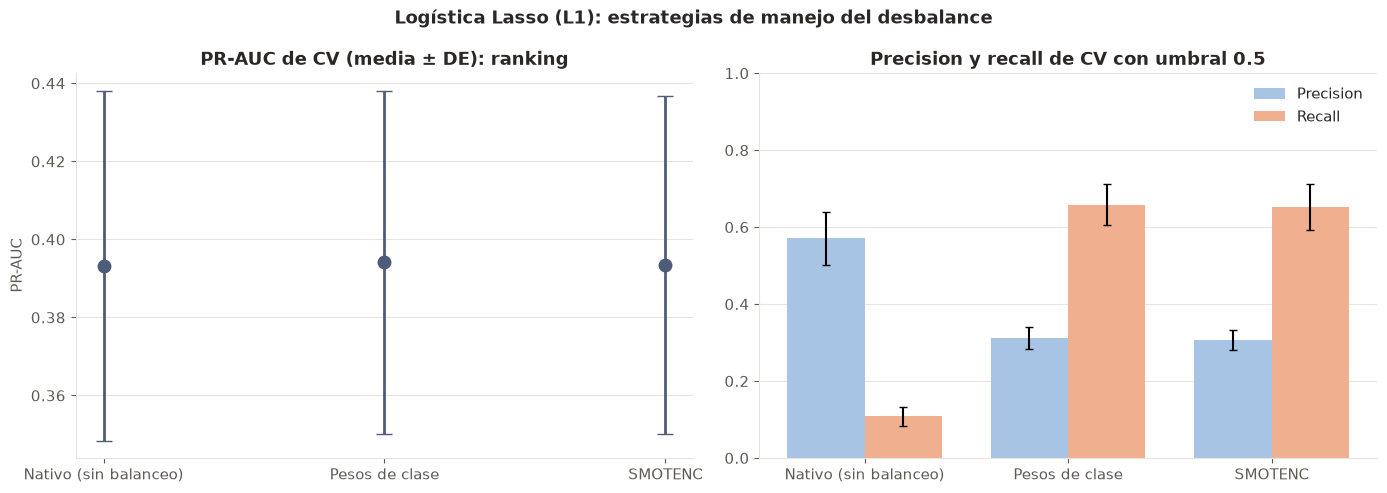

In [9]:
fig = graficar_estrategias(tabla, NOMBRES_CLF[CLAVE])
plt.show()

La gráfica confirma que las tres estrategias producen esencialmente el mismo modelo. La PR-AUC media es prácticamente idéntica (~0.39) y las barras de desviación se solapan por completo, así que ni los pesos de clase ni SMOTENC mejoran la capacidad de la Lasso para ordenar los positivos por encima de los negativos. Lo que cambia es el punto de operación con el umbral fijo de 0.5: el nativo casi no predice la clase minoritaria (precision ~0.57, recall ~0.11), mientras que los pesos de clase y SMOTENC desplazan las probabilidades hacia la clase positiva y llevan el recall a ~0.65 a costa de una precision de ~0.31.

**Coeficientes por estrategia** (variables estandarizadas; los iguales a 0 son variables descartadas por la Lasso)

In [10]:
coeficientes = pd.DataFrame({
    ESTRATEGIAS[estrategia]: coeficientes_logistica(pipeline).set_index("Variable")["Coeficiente"]
    for estrategia, pipeline in pipelines.items()
})
display(coeficientes.round(3))

# Variables descartadas por la Lasso (coeficiente exactamente 0)
pd.Series({
    estrategia: ", ".join(columna.index[columna == 0]) or "ninguna"
    for estrategia, columna in coeficientes.items()
}, name="Coeficientes en cero").to_frame()

,Nativo (sin balanceo),Pesos de clase,SMOTENC
Variable,,,
sleep_quality_index,0.511,0.558,0.694
avg_sleep_hours,-0.195,-0.204,-0.189
midsleep_weekend_hours,0.120,0.144,0.180
social_jetlag_hours,0.000,0.000,0.000
screen_time_index,0.045,0.079,0.081
sex_Girl,0.850,0.971,1.088


,Coeficientes en cero
Nativo (sin balanceo),social_jetlag_hours
Pesos de clase,social_jetlag_hours
SMOTENC,social_jetlag_hours


La Lasso lleva a cero el coeficiente de `social_jetlag_hours` en las tres estrategias: una vez se conocen las demás variables del sueño, el *social jetlag* no aporta información adicional. El resto de los coeficientes mantiene el signo en las tres estrategias. Ser mujer (`sex_Girl`, 0.85 a 1.09) es el predictor con mayor coeficiente, seguido de `sleep_quality_index` (0.51 a 0.69); más horas de sueño reducen el riesgo (`avg_sleep_hours`, ≈ −0.19 a −0.20), y un punto medio de sueño más tardío el fin de semana (`midsleep_weekend_hours`, 0.12 a 0.18) y el tiempo de pantalla (`screen_time_index`, 0.05 a 0.08) lo aumentan levemente. El coeficiente de `sex_Girl` no es directamente comparable con los demás, porque es una variable dummy (0/1) y no está estandarizada.

SMOTENC es la estrategia que más altera los coeficientes: refuerza `sleep_quality_index` (0.69) y `sex_Girl` (1.09).

### Selección del Mejor Modelo Logística Lasso

In [11]:
estrategia_ganadora, explicacion = elegir_mejor(tabla)

pd.Series({
    "Estrategia ganadora": ESTRATEGIAS[estrategia_ganadora],
    "PR-AUC de CV": f"{tabla.loc[estrategia_ganadora, 'PR-AUC media']:.4f} ± {tabla.loc[estrategia_ganadora, 'PR-AUC DE']:.4f}",
    "Hiperparámetros": formatear_hiperparametros(hiperparametros[estrategia_ganadora]),
    "Criterio": explicacion,
}, name=NOMBRES_CLF[CLAVE]).to_frame()

,Logística Lasso (L1)
Estrategia ganadora,Pesos de clase
PR-AUC de CV,0.3941 ± 0.0440
Hiperparámetros,C=0.07459
Criterio,Se elige 'pesos': tiene la mayor PR-AUC media de CV (0.3941 ± 0.0440).


Se eligen los pesos de clase, que tienen la PR-AUC media más alta (0.3941 ± 0.0440). Su ventaja sobre SMOTENC (0.0006) y el nativo (0.0008) es mucho menor que la desviación entre folds, así que en la práctica las tres estrategias son equivalentes. Con umbral 0.5 alcanza un recall de 0.659 con una precision de 0.312, aunque el umbral de operación se optimiza en la fase 3.

### Guardado

In [12]:
ganador = guardar_fase1(
    CLAVE, tabla, estrategia_ganadora, pipelines[estrategia_ganadora],
    hiperparametros[estrategia_ganadora], explicacion,
)